## Loading CIFAR-10

Load 50,000 training images and 10,000 test images. Each image has three color channels and a resolution of 32 × 32. The batch size is 64. The baseline uses ToTensor without normalization.

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader


# Baseline preprocessing: convert pixel values to a tensor in [0, 1].
transform = transforms.ToTensor()


train_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Shuffle training batches; keep test order fixed.
train_loader = DataLoader(
    train_data, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_data, batch_size=64, shuffle=False
)

images, labels = next(iter(train_loader))

print("Training images:", len(train_data))
print("Test images:", len(test_data))
print("Images tensor size:", images.shape)

100%|██████████| 170M/170M [25:25<00:00, 112kB/s]    


Training images: 50000
Test images: 10000
Images tensor size: torch.Size([64, 3, 32, 32])


## Visualizing Sample Images 
Display eight images with their ground-truth labels. Pixelation is expected because the original images are small.

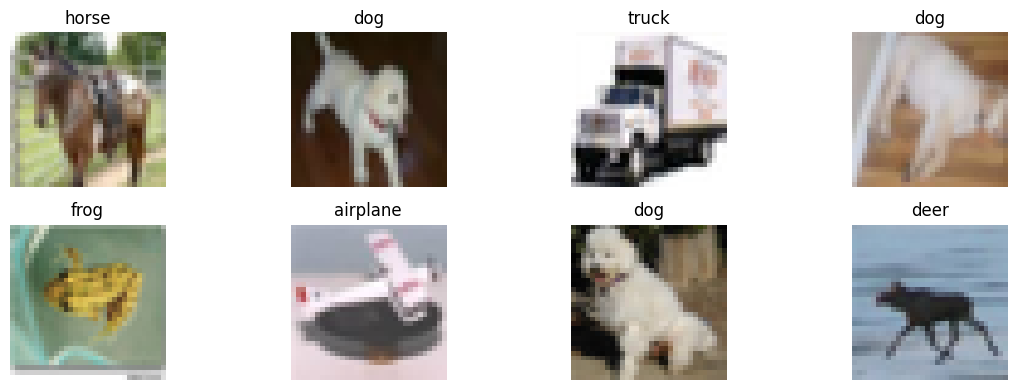

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].permute(1, 2, 0))
    plt.title(train_data.classes[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()


## Defining the Baseline CNN

Two convolutional blocks extract features. Max pooling reduces spatial dimensions from 32 to 16 and then 8. The classifier outputs ten unnormalized class scores (logits).

In [ ]:
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        
       # Convolution extracts features; pooling halves spatial dimensions.
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # After two pooling layers: 32 channels of size 8 x 8.

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = CNN().to(device)

print("Device:", device)
print(model)

Device: cpu
CNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


## Checking Output Dimensions

Verify that 64 input images produce 64 sets of ten class scores. This checks dimensions, not prediction quality.

In [6]:
model.eval()

with torch.no_grad():
    outputs = model(images.to(device))

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])


## Training and Evaluation Functions

Use cross-entropy loss and Adam. Training updates weights; evaluation disables gradient tracking and leaves weights unchanged. Loss is averaged over all samples, and accuracy is reported as a percentage.

In [ ]:

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


def train_one_epoch(model, loader, criterion, optimizer, device):
    
        # Enable training behavior before updating model weights.
    model.train()

    total_loss = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        
        # Clear old gradients before backpropagation.
        
        optimizer.zero_grad()

       # Compute gradients, then update parameters.
       
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_samples += images.size(0)

    return total_loss / total_samples


def test_model(model, loader, criterion, device):
    
        # Evaluate without parameter updates.
    model.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0
    
        # Disable gradient tracking during evaluation.

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)


            # Select the highest-scoring class for each image.
            predictions = outputs.argmax(dim=1)

            total_loss += loss.item() * images.size(0)
            total_correct += (predictions == labels).sum().item()
            total_samples += images.size(0)

    average_loss = total_loss / total_samples
    accuracy = 100 * total_correct / total_samples

    return average_loss, accuracy

## Baseline Experiment
Train for five epochs with Adam, learning rate 0.001, and batch size 64.

In [8]:
epochs = 5

train_losses = []
test_losses = []
test_accuracies = []

for epoch in range(epochs):
    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    test_loss, test_accuracy = test_model(
        model, test_loader, criterion, device
    )

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}%",
        flush=True
    )

Epoch 1/5 | Train Loss: 1.5748 | Test Loss: 1.3288 | Test Accuracy: 52.96%
Epoch 2/5 | Train Loss: 1.2432 | Test Loss: 1.1745 | Test Accuracy: 58.36%
Epoch 3/5 | Train Loss: 1.1011 | Test Loss: 1.0772 | Test Accuracy: 62.10%
Epoch 4/5 | Train Loss: 1.0034 | Test Loss: 1.0288 | Test Accuracy: 63.80%
Epoch 5/5 | Train Loss: 0.9287 | Test Loss: 0.9787 | Test Accuracy: 65.79%


## Baseline Learning Curves
Plot training loss, test loss, and test accuracy, and report the final recorded values.

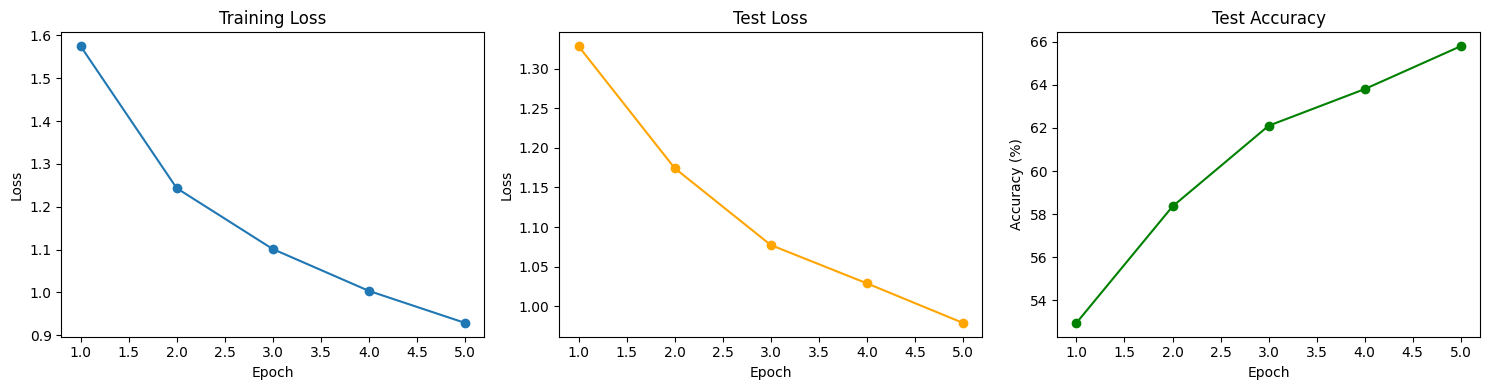

Final Train Loss: 0.9287
Final Test Loss: 0.9787
Final Test Accuracy: 65.79%


In [9]:
epoch_numbers = range(1, len(train_losses) + 1)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(epoch_numbers, train_losses, marker="o")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 3, 2)
plt.plot(epoch_numbers, test_losses, marker="o", color="orange")
plt.title("Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 3, 3)
plt.plot(epoch_numbers, test_accuracies, marker="o", color="green")
plt.title("Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.tight_layout()
plt.show()

print(f"Final Train Loss: {train_losses[-1]:.4f}")
print(f"Final Test Loss: {test_losses[-1]:.4f}")
print(f"Final Test Accuracy: {test_accuracies[-1]:.2f}%")

In [10]:
baseline_results = {
    "train_losses": train_losses.copy(),
    "test_losses": test_losses.copy(),
    "test_accuracies": test_accuracies.copy()
}

## Data Augmentation and Normalization
Training images receive random horizontal flips, resized crops, rotation, and color jitter. Both training and test images are normalized using mean 0.5 and standard deviation 0.5 per channel. These are chosen constants, not estimated dataset statistics. Test images do not receive random augmentation.

In [ ]:

mean = (0.5, 0.5, 0.5)
std = (0.5, 0.5, 0.5)

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomResizedCrop(
        size=32,
        scale=(0.8, 1.0)
    ),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Test preprocessing is deterministic and uses matching normalization.
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_data_aug = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=train_transform
)

test_data_aug = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=test_transform
)

train_loader_aug = DataLoader(
    train_data_aug, batch_size=64, shuffle=True
)

test_loader_aug = DataLoader(
    test_data_aug, batch_size=64, shuffle=False
)

print("Augmented training data is ready.")

Augmented training data is ready.


## Augmented CNN Experiment
Initialize a new baseline CNN and train for five epochs with learning rate 0.001 and batch size 64. Compared with the baseline, this experiment changes both augmentation and normalization, so their individual effects cannot be separated.

In [12]:

model_aug = CNN().to(device)

optimizer_aug = torch.optim.Adam(
    model_aug.parameters(), lr=0.001
)

epochs_aug = 5

aug_train_losses = []
aug_test_losses = []
aug_test_accuracies = []

for epoch in range(epochs_aug):
    train_loss = train_one_epoch(
        model_aug,
        train_loader_aug,
        criterion,
        optimizer_aug,
        device
    )

    test_loss, test_accuracy = test_model(
        model_aug,
        test_loader_aug,
        criterion,
        device
    )

    aug_train_losses.append(train_loss)
    aug_test_losses.append(test_loss)
    aug_test_accuracies.append(test_accuracy)

    print(
        f"Epoch {epoch + 1}/{epochs_aug} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}%",
        flush=True
    )

Epoch 1/5 | Train Loss: 1.5500 | Test Loss: 1.3471 | Test Accuracy: 51.55%
Epoch 2/5 | Train Loss: 1.2777 | Test Loss: 1.1659 | Test Accuracy: 59.04%
Epoch 3/5 | Train Loss: 1.1525 | Test Loss: 1.0235 | Test Accuracy: 64.17%
Epoch 4/5 | Train Loss: 1.0868 | Test Loss: 0.9793 | Test Accuracy: 65.82%
Epoch 5/5 | Train Loss: 1.0338 | Test Loss: 0.9724 | Test Accuracy: 66.01%


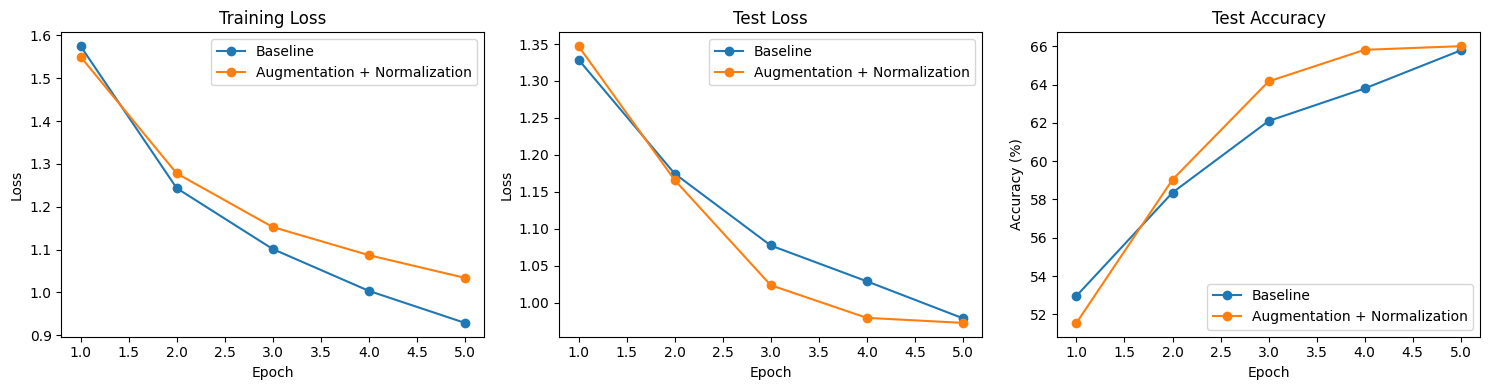

Experiment 2 — Final Results
Train Loss: 1.0338
Test Loss: 0.9724
Test Accuracy: 66.01%


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

comparisons = [
    (
        baseline_results["train_losses"],
        aug_train_losses,
        "Training Loss",
        "Loss"
    ),
    (
        baseline_results["test_losses"],
        aug_test_losses,
        "Test Loss",
        "Loss"
    ),
    (
        baseline_results["test_accuracies"],
        aug_test_accuracies,
        "Test Accuracy",
        "Accuracy (%)"
    )
]

for ax, (baseline, augmented, title, ylabel) in zip(
    axes, comparisons
):
    ax.plot(
        range(1, len(baseline) + 1),
        baseline,
        marker="o",
        label="Baseline"
    )

    ax.plot(
        range(1, len(augmented) + 1),
        augmented,
        marker="o",
        label="Augmentation + Normalization"
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()

plt.tight_layout()
plt.show()

print("Experiment 2 — Final Results")
print(f"Train Loss: {aug_train_losses[-1]:.4f}")
print(f"Test Loss: {aug_test_losses[-1]:.4f}")
print(f"Test Accuracy: {aug_test_accuracies[-1]:.2f}%")

## Alternative CNN Architecture

Use three convolutional blocks with 32, 64, and 128 channels. Train with the same augmentation, normalization, learning rate, batch size, and epoch count as the augmented baseline.

In [ ]:
class CNN_V2(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        
        # Three pooling layers reduce 32 x 32 images to 4 x 4 features.

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model_v2 = CNN_V2().to(device)

optimizer_v2 = torch.optim.Adam(
    model_v2.parameters(), lr=0.001
)

print(model_v2)

CNN_V2(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [15]:
v2_train_losses = []
v2_test_losses = []
v2_test_accuracies = []

for epoch in range(5):
    train_loss = train_one_epoch(
        model_v2,
        train_loader_aug,
        criterion,
        optimizer_v2,
        device
    )

    test_loss, test_accuracy = test_model(
        model_v2,
        test_loader_aug,
        criterion,
        device
    )

    v2_train_losses.append(train_loss)
    v2_test_losses.append(test_loss)
    v2_test_accuracies.append(test_accuracy)

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}%",
        flush=True
    )

Epoch 1/5 | Train Loss: 1.5183 | Test Loss: 1.1737 | Test Accuracy: 57.84%
Epoch 2/5 | Train Loss: 1.1636 | Test Loss: 1.0051 | Test Accuracy: 64.65%
Epoch 3/5 | Train Loss: 1.0211 | Test Loss: 0.9679 | Test Accuracy: 66.81%
Epoch 4/5 | Train Loss: 0.9317 | Test Loss: 0.9042 | Test Accuracy: 69.06%
Epoch 5/5 | Train Loss: 0.8684 | Test Loss: 0.7856 | Test Accuracy: 72.75%


##  Comparing the First Three Experiments
Compare the recorded learning curves. The architecture comparison uses the same preprocessing, but initialization and random draws are not controlled across these earlier runs.

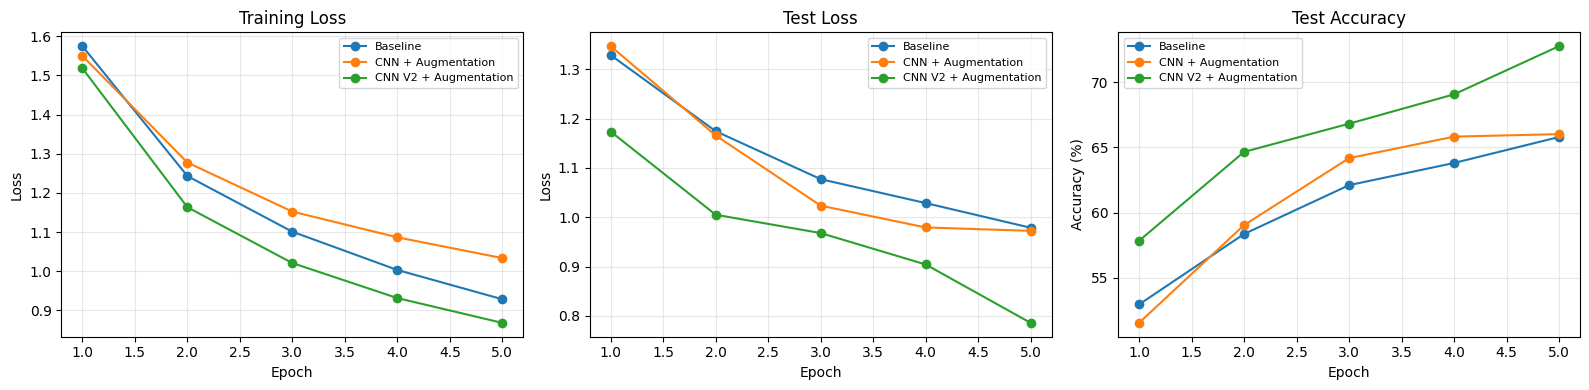

Final results
---------------------------------------------------------------------------
Baseline: Train Loss=0.9287, Test Loss=0.9787, Test Accuracy=65.79%
CNN + Augmentation: Train Loss=1.0338, Test Loss=0.9724, Test Accuracy=66.01%
CNN V2 + Augmentation: Train Loss=0.8684, Test Loss=0.7856, Test Accuracy=72.75%


In [16]:
experiments = {
    "Baseline": (
        baseline_results["train_losses"],
        baseline_results["test_losses"],
        baseline_results["test_accuracies"]
    ),
    "CNN + Augmentation": (
        aug_train_losses,
        aug_test_losses,
        aug_test_accuracies
    ),
    "CNN V2 + Augmentation": (
        v2_train_losses,
        v2_test_losses,
        v2_test_accuracies
    )
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

titles = ["Training Loss", "Test Loss", "Test Accuracy"]
ylabels = ["Loss", "Loss", "Accuracy (%)"]

for name, histories in experiments.items():
    for i, history in enumerate(histories):
        axes[i].plot(
            range(1, len(history) + 1),
            history,
            marker="o",
            label=name
        )

for i, ax in enumerate(axes):
    ax.set_title(titles[i])
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabels[i])
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Final results")
print("-" * 75)

for name, (train_loss, test_loss, accuracy) in experiments.items():
    print(
        f"{name}: "
        f"Train Loss={train_loss[-1]:.4f}, "
        f"Test Loss={test_loss[-1]:.4f}, "
        f"Test Accuracy={accuracy[-1]:.2f}%"
    )

## Saving Initial Results
Save the first three model state dictionaries and recorded histories. Loading a state dictionary also requires its corresponding model class definition.

In [17]:
torch.save(
    {
        "baseline_model": model.state_dict(),
        "augmented_model": model_aug.state_dict(),
        "v2_model": model_v2.state_dict(),
        "results": experiments
    },
    "cnn_experiments.pth"
)

print("Models and results saved successfully.")

Models and results saved successfully.


## Gaussian Noise Experiment

Add Gaussian noise with standard deviation 0.03 before normalization, clipping values to [0, 1]. Noise is applied only to training images. CIFAR-10 already returns PIL images: the initial ToTensor → ToPILImage round trip is included only to demonstrate the requested transform and is unnecessary for the production pipeline.

In [ ]:
class AddGaussianNoise:
    def __init__(self, std=0.03):
        self.std = std

    def __call__(self, tensor):
             # Add noise before normalization; preserve valid pixel bounds.
             
        noise = torch.randn_like(tensor) * self.std
        return (tensor + noise).clamp(0, 1)


noise_transform = transforms.Compose([
   
    transforms.ToTensor(),
    transforms.ToPILImage(),

    transforms.RandomHorizontalFlip(),
    transforms.RandomResizedCrop(32, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),

    transforms.ToTensor(),
    AddGaussianNoise(std=0.03),
    transforms.Normalize(mean, std)
])

noise_train_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=noise_transform
)

noise_train_loader = DataLoader(
    noise_train_data,
    batch_size=64,
    shuffle=True
)

print("Noise training data is ready.")

Noise training data is ready.


## Reusable Experiment Function
Each call creates a new baseline CNN and Adam optimizer. A seed of 42 is set for these later runs only. Earlier experiments did not use this seed, so comparisons with them are exploratory rather than fully controlled.

In [ ]:
def run_experiment(train_loader, learning_rate, epochs=5):
    
    
        
    # This seed applies to these later experiments, not earlier saved runs.
    
    torch.manual_seed(42)

    new_model = CNN().to(device)

    new_optimizer = torch.optim.Adam(
        new_model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_losses": [],
        "test_losses": [],
        "test_accuracies": []
    }

    for epoch in range(epochs):
        train_loss = train_one_epoch(
            new_model,
            train_loader,
            criterion,
            new_optimizer,
            device
        )

        test_loss, test_accuracy = test_model(
            new_model,
            test_loader_aug,
            criterion,
            device
        )

        history["train_losses"].append(train_loss)
        history["test_losses"].append(test_loss)
        history["test_accuracies"].append(test_accuracy)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Accuracy: {test_accuracy:.2f}%",
            flush=True
        )

    return new_model, history

## Noise Experiment
Train the baseline CNN for five epochs with augmentation, normalization, Gaussian noise, learning rate 0.001, and batch size 64

In [20]:
noise_model, noise_results = run_experiment(
    train_loader=noise_train_loader,
    learning_rate=0.001
)

Epoch 1/5 | Train Loss: 1.5500 | Test Loss: 1.3075 | Test Accuracy: 52.93%
Epoch 2/5 | Train Loss: 1.3170 | Test Loss: 1.1513 | Test Accuracy: 58.82%
Epoch 3/5 | Train Loss: 1.2114 | Test Loss: 1.0589 | Test Accuracy: 62.46%
Epoch 4/5 | Train Loss: 1.1268 | Test Loss: 1.0320 | Test Accuracy: 63.18%
Epoch 5/5 | Train Loss: 1.0729 | Test Loss: 0.9853 | Test Accuracy: 65.18%


## Learning Rate Experiment
Train the baseline CNN for five epochs using augmentation and normalization without added noise. Lower the learning rate to 0.0005 and keep batch size 64. The corresponding earlier 0.001 run did not use the same seed, so the difference cannot be attributed solely to learning rate.

In [21]:
lr_model, lr_results = run_experiment(
    train_loader=train_loader_aug,
    learning_rate=0.0005
)

Epoch 1/5 | Train Loss: 1.6219 | Test Loss: 1.3813 | Test Accuracy: 50.70%
Epoch 2/5 | Train Loss: 1.3678 | Test Loss: 1.2975 | Test Accuracy: 54.04%
Epoch 3/5 | Train Loss: 1.2738 | Test Loss: 1.1785 | Test Accuracy: 57.63%
Epoch 4/5 | Train Loss: 1.2004 | Test Loss: 1.1090 | Test Accuracy: 60.80%
Epoch 5/5 | Train Loss: 1.1493 | Test Loss: 1.0836 | Test Accuracy: 61.34%


## Final Comparison
Compare the five recorded experiments. All use five epochs, batch size 64, Adam, and cross-entropy loss. Batch size and epoch count were held constant; varying them would be an optional extension.

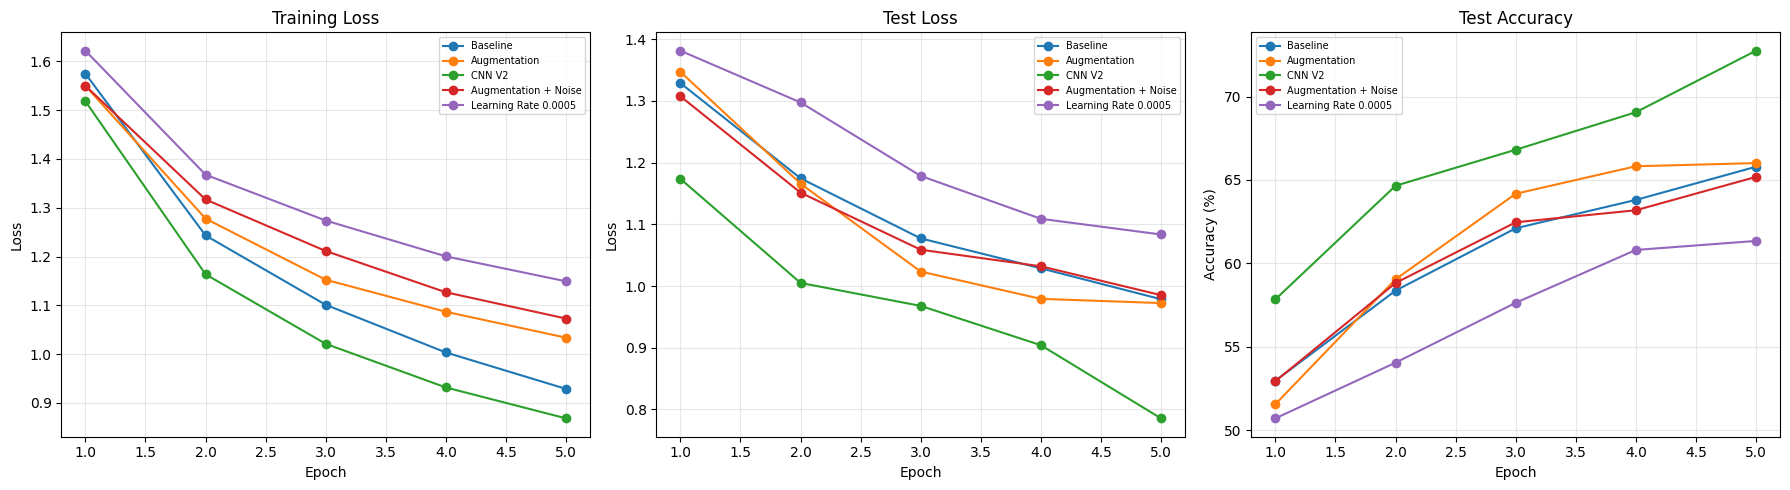

Baseline | Train Loss: 0.9287 | Test Loss: 0.9787 | Test Accuracy: 65.79%
Augmentation | Train Loss: 1.0338 | Test Loss: 0.9724 | Test Accuracy: 66.01%
CNN V2 | Train Loss: 0.8684 | Test Loss: 0.7856 | Test Accuracy: 72.75%
Augmentation + Noise | Train Loss: 1.0729 | Test Loss: 0.9853 | Test Accuracy: 65.18%
Learning Rate 0.0005 | Train Loss: 1.1493 | Test Loss: 1.0836 | Test Accuracy: 61.34%


In [22]:
all_results = {
    "Baseline": baseline_results,

    "Augmentation": {
        "train_losses": aug_train_losses,
        "test_losses": aug_test_losses,
        "test_accuracies": aug_test_accuracies
    },

    "CNN V2": {
        "train_losses": v2_train_losses,
        "test_losses": v2_test_losses,
        "test_accuracies": v2_test_accuracies
    },

    "Augmentation + Noise": noise_results,
    "Learning Rate 0.0005": lr_results
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    ("train_losses", "Training Loss", "Loss"),
    ("test_losses", "Test Loss", "Loss"),
    ("test_accuracies", "Test Accuracy", "Accuracy (%)")
]

for ax, (key, title, ylabel) in zip(axes, metrics):
    for name, result in all_results.items():
        values = result[key]

        ax.plot(
            range(1, len(values) + 1),
            values,
            marker="o",
            label=name
        )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("experiments_comparison.png", dpi=200)
plt.show()

for name, result in all_results.items():
    print(
        f"{name} | "
        f"Train Loss: {result['train_losses'][-1]:.4f} | "
        f"Test Loss: {result['test_losses'][-1]:.4f} | "
        f"Test Accuracy: {result['test_accuracies'][-1]:.2f}%"
    )

## Saving Models and Results
Save histories to JSON, the comparison plot to PNG in the preceding cell, and model weights to a PyTorch file. Save and upload the source notebook separately to GitHub; saving weights does not replace source-code submission.

In [23]:
import json

with open("experiment_results.json", "w") as file:
    json.dump(all_results, file, indent=4)

models_to_save = {
    "baseline": model,
    "augmentation": model_aug,
    "cnn_v2": model_v2,
    "noise": noise_model,
    "lower_learning_rate": lr_model
}

torch.save(
    {
        name: trained_model.state_dict()
        for name, trained_model in models_to_save.items()
    },
    "all_cnn_models.pth"
)

print("Results, comparison plot, and models saved.")

Results, comparison plot, and models saved.


| Experiment | Final train loss | Final test loss | Final test accuracy |
|---|---:|---:|---:|
| Baseline | 0.9287 | 0.9787 | 65.79% |
| Augmentation + normalization | 1.0338 | 0.9724 | 66.01% |
| CNN V2 + augmentation + normalization | 0.8684 | 0.7856 | 72.75% |
| Augmentation + normalization + noise | 1.0729 | 0.9853 | 65.18% |
| Augmentation + normalization, learning rate 0.0005 | 1.1493 | 1.0836 | 61.34% |

CNN V2 with augmentation and normalization achieved the highest
observed final test accuracy of 72.75%, with a training loss of
0.8684 and a test loss of 0.7856.

It used Adam, a learning rate of 0.001, a batch size of 64,
and five epochs. Gaussian noise and the lower learning rate
did not improve accuracy in the recorded runs.

Each configuration was run once, and random seeds were not
controlled across all experiments, so these comparisons
should be interpreted as exploratory.